# Frames and powder patterns on the GPU, handed to torch, jax, cupy, numba, pycuda and tensorflow

bslz4_to_sparse.cuda decodes on an NVIDIA GPU.  With the driver backend (BSLZ4_CUDA_BACKEND=driver)
it needs no CUDA toolkit, compiler or cupy: the kernels come compiled in the package (a fatbin with
code for every GPU generation from Fermi on) and are launched through the CUDA driver, libcuda, with
ctypes.  Two calls keep their results on the GPU:

    decompress(chunks)   the dense frames: (nframes, ni, nj) of the pixel dtype
    integrate(chunks)    each frame's powder, the sums of pyFAI's sparse matrix: (nframes, nbins)

The arrays they return follow the two conventions GPU libraries use to share memory,
__cuda_array_interface__ (cupy, numba, pycuda, torch) and DLPack (torch, jax, tensorflow, cupy), so
a library takes them without a copy: it works on the same GPU memory.  The data is complete when
the call returns.  This example gives the frames, a 1D powder pattern and a 2D (q x azimuth) cake
to each of these libraries that is installed, computes something there, and checks it against the
CPU (h5py's decompression and pyFAI's integration).  A library uses the device's primary context,
as the driver backend does (pycuda needs to be told: retain_primary_context).

In [1]:
import os

In [2]:
os.environ["BSLZ4_CUDA_BACKEND"] = "driver"  # set before bslz4_to_sparse.cuda is imported
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")  # jax: allocate as needed
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")  # tensorflow: errors only

'3'

In [3]:
import h5py
import hdf5plugin  # registers the bitshuffle filter, so that h5py can decompress too
import matplotlib.pyplot as plt
import numpy as np
import pyFAI
from pyFAI.method_registry import IntegrationMethod

from bslz4_to_sparse import cuda

In [4]:
h5filename = "eiger_0000.h5"  # your file: bitshuffle-lz4 (8 kB blocks), one frame per chunk
h5dataset = "/entry_0000/ESRF-ID11/eiger/data"  # the (nframes, ni, nj) dataset inside it
mask_filename = (
    "mask.h5"  # your detector mask: a dataset "mask", pyFAI's convention (non-zero = masked)
)
poni_filename = "calib.poni"  # your pyFAI geometry
nframes = 16

In [5]:
with h5py.File(h5filename, "r") as h5:
    ds = h5[h5dataset]
    dtype = ds.dtype
    n = min(nframes, ds.shape[0])
    chunks = [ds.id.read_direct_chunk((i, 0, 0))[1] for i in range(n)]
    frames = ds[:n]  # h5py's own decompression, on the CPU: the reference
with h5py.File(mask_filename, "r") as h5:
    bad = h5["mask"][()] != 0  # the masked pixels
mask = (~bad).astype(np.uint8)

pyFAI's sparse matrices (CSC), 1D and 2D, and their normalisation (an image of ones)

In [6]:
ai = pyFAI.load(poni_filename)
ones = np.ones(frames.shape[1:], np.float32)
m1 = IntegrationMethod.select_one_available(("bbox", "csc", "cython"), dim=1)
m2 = IntegrationMethod.select_one_available(("bbox", "csc", "cython"), dim=2)
nq, nazim = 500, 36
norm1 = np.asarray(ai.integrate1d(ones, nq, unit="q_nm^-1", method=m1, mask=bad).sum_normalization)
ai.integrate2d(ones, nq, nazim, unit="q_nm^-1", method=m2, mask=bad)
engine1, engine2 = ai.engines[m1].engine, ai.engines[m2].engine

On the GPU: the frames, the 1D powder and the 2D cake of every frame

In [7]:
gpu1 = cuda.chunk2sparseCSC(mask, engine1, dtype)
gpu2 = cuda.chunk2sparseCSC(mask, engine2, dtype)
d_frames = gpu1.decompress(chunks)  # (n, ni, nj) uint16
d_powder = gpu1.integrate(chunks)  # (n, nq) float64: sum of weight x pixel per bin
d_cake = gpu2.integrate(chunks)  # (n, nq * nazim) float64, q-major as pyFAI's matrix
print("GPU:", cuda.device_name(0))
print("GPU arrays:", d_frames.shape, d_frames.dtype, d_powder.shape, d_cake.shape)
ptr = d_frames.__cuda_array_interface__["data"][0]
assert (d_frames.get() == frames).all()  # .get(): a host copy, without any library
ref1 = ai.integrate1d(frames[0], nq, unit="q_nm^-1", method=m1, mask=bad)
ref2 = ai.integrate2d(frames[0], nq, nazim, unit="q_nm^-1", method=m2, mask=bad)
assert np.allclose(d_powder[:1].get()[0], ref1.sum_signal, rtol=1e-9, atol=0)
assert np.allclose(d_cake[:1].get()[0].reshape(nq, nazim).T, ref2.sum_signal, rtol=1e-9, atol=0)
print("frame 0 equals h5py's frame; its powder and cake equal pyFAI's sum_signal")

GPU: NVIDIA L40S
GPU arrays: (16, 2162, 2068) uint16 (16, 500) (16, 18000)


frame 0 equals h5py's frame; its powder and cake equal pyFAI's sum_signal


In [8]:
counts = np.count_nonzero((frames > 3) & ~bad, axis=(1, 2))  # pixels above 3, for numba below
host_cake = d_cake.get().reshape(n, nq, nazim)
results = {}  # library -> what it computed, for the summary

In [9]:
def with_cupy():
    import cupy as cp

    x = cp.asarray(d_frames)  # __cuda_array_interface__: no copy
    assert x.data.ptr == ptr
    mean = x.mean(axis=0, dtype=cp.float64)  # the mean frame, on the GPU
    assert np.allclose(mean.get(), frames.mean(axis=0, dtype=np.float64))
    return "mean frame of %d, same memory" % n

In [10]:
def with_torch():
    import torch

    p = torch.from_dlpack(d_powder)  # DLPack: no copy
    intensity = p / torch.as_tensor(norm1, device=p.device).clamp(min=1e-30)  # pyFAI's intensity
    assert np.allclose(intensity[0].cpu().numpy(), ref1.intensity, rtol=1e-6, atol=0)
    x = torch.as_tensor(d_frames, device="cuda")  # or __cuda_array_interface__
    assert x.data_ptr() == ptr
    return "normalised 1D patterns, (%d, %d), same memory" % tuple(intensity.shape)

In [11]:
def with_jax():
    import jax
    import jax.numpy as jnp

    c = jax.dlpack.from_dlpack(d_cake).reshape(n, nq, nazim)  # DLPack: no copy
    spread = jnp.std(c, axis=2) / jnp.maximum(jnp.mean(c, axis=2), 1e-30)  # azimuthal variation
    want = host_cake.std(axis=2) / np.maximum(host_cake.mean(axis=2), 1e-30)
    assert np.allclose(np.asarray(spread), want, rtol=1e-6, atol=1e-9)
    return "azimuthal spread of each q bin, (%d, %d)" % spread.shape

In [12]:
def with_numba():
    from numba import cuda as ncuda

    @ncuda.jit
    def count_above(fr, msk, cut, out):  # one thread per (frame, row): pixels above the cut
        f, i = ncuda.grid(2)
        if f < fr.shape[0] and i < fr.shape[1]:
            k = 0
            for j in range(fr.shape[2]):
                if fr[f, i, j] > cut and msk[i, j]:
                    k += 1
            ncuda.atomic.add(out, f, k)

    x = ncuda.as_cuda_array(d_frames)  # __cuda_array_interface__: no copy
    assert x.device_ctypes_pointer.value == ptr
    out = ncuda.to_device(np.zeros(n, np.int64))
    count_above[(n, (x.shape[1] + 127) // 128), (1, 128)](x, ncuda.to_device(mask), 3, out)
    assert (out.copy_to_host() == counts).all()
    return "a kernel of its own: pixels above 3 per frame"

In [13]:
def with_pycuda():
    import pycuda.driver as drv
    import pycuda.gpuarray as gpuarray

    drv.init()
    ctx = drv.Device(0).retain_primary_context()  # the context the arrays live in
    ctx.push()
    try:
        x = gpuarray.GPUArray(d_frames.shape, d_frames.dtype, gpudata=ptr)  # no copy
        top = [int(gpuarray.max(x[i]).get()) for i in range(n)]
    finally:
        ctx.pop()
    assert top == [int(f.max()) for f in frames]
    return "brightest pixel of each frame"

In [14]:
def with_tensorflow():
    import tensorflow as tf

    for g in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(g, True)
    x = tf.experimental.dlpack.from_dlpack(d_frames.__dlpack__())  # DLPack: no copy
    total = tf.reduce_sum(tf.cast(x, tf.float64), axis=(1, 2)).numpy()
    assert np.allclose(total, frames.sum(axis=(1, 2), dtype=np.float64))
    return "sum of each frame"

In [15]:
for name, fn in [("cupy", with_cupy), ("torch", with_torch), ("jax", with_jax),
                 ("numba", with_numba), ("pycuda", with_pycuda), ("tensorflow", with_tensorflow)]:
    try:
        __import__(name)
    except ImportError:
        results[name] = "not installed"
        continue
    results[name] = fn()
for name, what in results.items():
    print("%-10s %s" % (name, what))

cupy       mean frame of 16, same memory
torch      normalised 1D patterns, (16, 500), same memory
jax        azimuthal spread of each q bin, (16, 500)
numba      a kernel of its own: pixels above 3 per frame
pycuda     brightest pixel of each frame
tensorflow sum of each frame


The 1D pattern and the cake of all the frames, as the GPU gave them

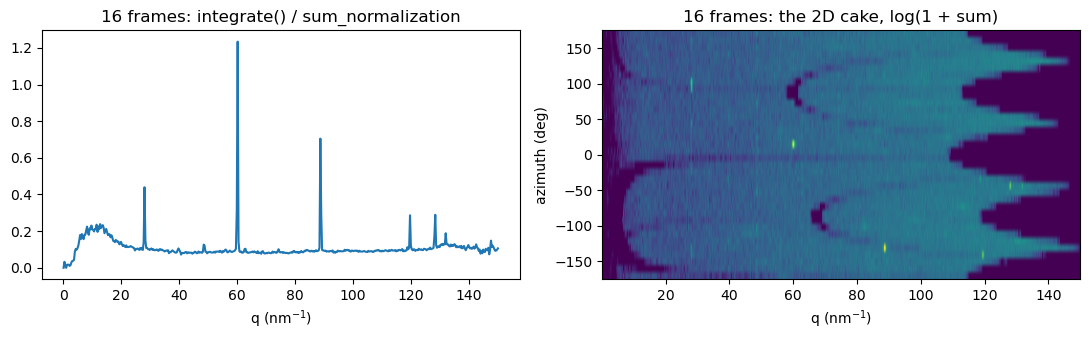

In [16]:
q, chi = ref2.radial, ref2.azimuthal
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(ref1.radial, d_powder.get().sum(axis=0) / np.maximum(norm1, 1e-30))
axes[0].set_xlabel("q (nm$^{-1}$)")
axes[0].set_title("%d frames: integrate() / sum_normalization" % n)
axes[1].imshow(np.log1p(host_cake.sum(axis=0).T), aspect="auto", origin="lower",
               extent=(q[0], q[-1], chi[0], chi[-1]))
axes[1].set_xlabel("q (nm$^{-1}$)")
axes[1].set_ylabel("azimuth (deg)")
axes[1].set_title("%d frames: the 2D cake, log(1 + sum)" % n)
plt.tight_layout()
plt.show()